In [ ]:
#Environment & Library Imports
import os
import glob
from PIL import Image
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


Dataset Summary:
Class: cataract               | Count: 1038
Class: diabetic_retinopathy   | Count: 1098
Class: glaucoma               | Count: 1007
Class: normal                 | Count: 1074
Total number of images: 4217


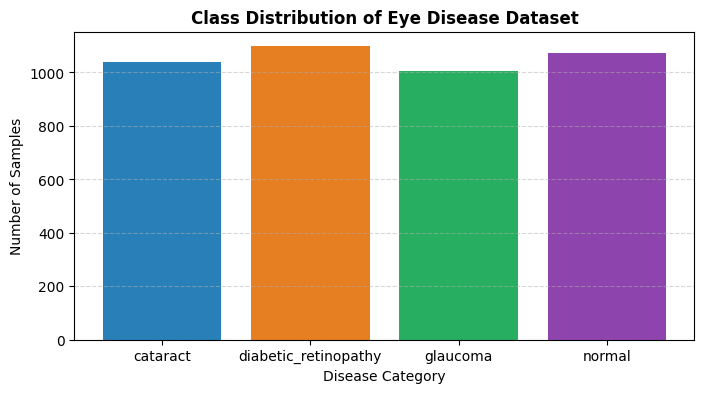

In [ ]:
#Dataset Statistics & Class Distribution
data_dir = "data"

class_counts = {}
for category in sorted(os.listdir(data_dir)):
    cat_path = os.path.join(data_dir, category)
    if os.path.isdir(cat_path):
        class_counts[category] = len(os.listdir(cat_path))

print("Dataset Summary:")
for cls, count in class_counts.items():
    print(f"Class: {cls:22s} | Count: {count}")
print(f"Total number of images: {sum(class_counts.values())}")

# Plot class balance
plt.figure(figsize=(8, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=['#2980b9', '#e67e22', '#27ae60', '#8e44ad'])
plt.title("Class Distribution of Eye Disease Dataset", fontsize=12, fontweight='bold')
plt.xlabel("Disease Category")
plt.ylabel("Number of Samples")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


In [3]:
# Inspect dimensions and color modes of representative samples
for category in sorted(os.listdir(data_dir)):
    cat_path = os.path.join(data_dir, category)
    if os.path.isdir(cat_path):
        sample_file = os.listdir(cat_path)[0]
        sample_path = os.path.join(cat_path, sample_file)
        with Image.open(sample_path) as img:
            print(f"Class: {category:22s} | Resolution: {img.size} (WxH) | Mode: {img.mode}")


Class: cataract               | Resolution: (512, 512) (WxH) | Mode: RGB
Class: diabetic_retinopathy   | Resolution: (512, 512) (WxH) | Mode: RGB
Class: glaucoma               | Resolution: (512, 512) (WxH) | Mode: RGB
Class: normal                 | Resolution: (512, 512) (WxH) | Mode: RGB


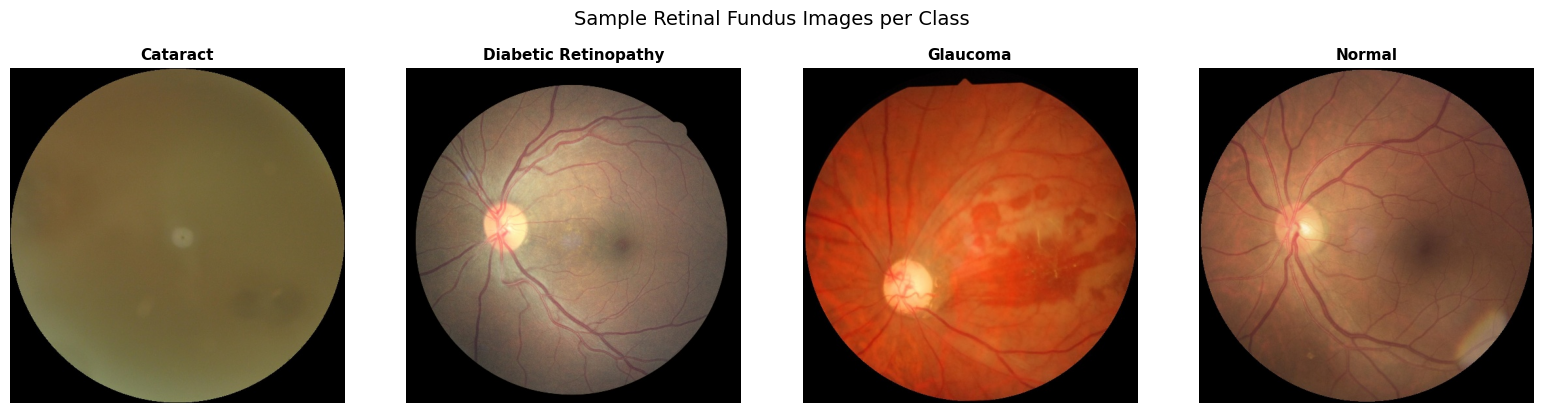

In [ ]:
# Visual Inspection of Samples Across Classes
categories = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
fig, axes = plt.subplots(1, len(categories), figsize=(16, 4))

for idx, category in enumerate(categories):
    cat_path = os.path.join(data_dir, category)
    sample_file = os.listdir(cat_path)[0]
    img = Image.open(os.path.join(cat_path, sample_file))
    
    axes[idx].imshow(img)
    axes[idx].set_title(category.replace('_', ' ').title(), fontsize=11, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle("Sample Retinal Fundus Images per Class", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()
